# 5 · A parameter sweep

How much background input does the toy network model need to fire? Run it for several values of one number and plot the rates, in Python. About five minutes.

Open this notebook in your project folder, the one with `configs/` ([tutorial 1](1_first_run.md)): download it with the button at the top of this page, then start `jupyter lab` there.

## The sweep

A plain loop. Each value gets a network model folder of its own, a copy of the toy with one number changed, as in [tutorial 2](2_change_a_parameter.md), so every network you ran stays a folder you can open and run again.

In [1]:
import shutil
from pathlib import Path

import yaml

from microcircuit_lab import Simulation, read_run
from microcircuit_lab.analysis import compute_population_firing_rates

indegrees = [600, 700, 800, 900, 1000, 1100, 1200]
rates = {}
for indegree in indegrees:
    # A copy of the toy with another indegree.
    name = f"toy_indegree_{indegree}"
    folder = Path("configs/network") / name
    shutil.copytree("configs/network/toy", folder, dirs_exist_ok=True)
    background_file = folder / "poisson_background.yaml"
    background = yaml.safe_load(background_file.read_text())
    for entry in background["poisson_background"].values():
        entry["indegree"] = indegree
    background_file.write_text(yaml.safe_dump(background, sort_keys=False))

    # Run it with the toy's settings, and keep its mean rates.
    simulation = Simulation.from_yaml(network_name=name, simulation_name="toy")
    simulation.run()
    rates[indegree] = compute_population_firing_rates(read_run(simulation.output_dir), begin=200.0)


             -- N E S T --

 Copyright (C) 2004 The NEST Initiative

 Version: 3.10.0
 Built  : Jun 10 2026 07:01:20

 This program is provided AS IS and comes with NO WARRANTY.
 See the file LICENSE for details.

 Problems or suggestions?
   Visit https://www.nest-simulator.org

 Type 'nest.help()' to find out more about NEST.

[INFO] [2026-11-20 20:53:28] Temporal resolution changed from 0.1 to 0.1 ms.


[INFO] [2026-11-20 20:53:28] Preparing 1012 nodes for simulation.
[INFO] [2026-11-20 20:53:28] Number of local nodes: 1012
Simulation time (ms): 1000
Number of OpenMP threads: 4
Not using MPI
[INFO] [2026-11-20 20:53:29] Simulation finished.
[INFO] [2026-11-20 20:53:29] Temporal resolution changed from 0.1 to 0.1 ms.
[INFO] [2026-11-20 20:53:29] Preparing 1012 nodes for simulation.


[INFO] [2026-11-20 20:53:29] Number of local nodes: 1012
Simulation time (ms): 1000
Number of OpenMP threads: 4
Not using MPI
[INFO] [2026-11-20 20:53:29] Simulation finished.
[INFO] [2026-11-20 20:53:29] Temporal resolution changed from 0.1 to 0.1 ms.
[INFO] [2026-11-20 20:53:29] Preparing 1012 nodes for simulation.
[INFO] [2026-11-20 20:53:29] Number of local nodes: 1012
Simulation time (ms): 1000
Number of OpenMP threads: 4
Not using MPI
[INFO] [2026-11-20 20:53:29] Simulation finished.


[INFO] [2026-11-20 20:53:29] Temporal resolution changed from 0.1 to 0.1 ms.
[INFO] [2026-11-20 20:53:29] Preparing 1012 nodes for simulation.
[INFO] [2026-11-20 20:53:29] Number of local nodes: 1012
Simulation time (ms): 1000
Number of OpenMP threads: 4
Not using MPI
[INFO] [2026-11-20 20:53:29] Simulation finished.


[INFO] [2026-11-20 20:53:29] Temporal resolution changed from 0.1 to 0.1 ms.
[INFO] [2026-11-20 20:53:29] Preparing 1012 nodes for simulation.
[INFO] [2026-11-20 20:53:29] Number of local nodes: 1012
Simulation time (ms): 1000
Number of OpenMP threads: 4
Not using MPI
[INFO] [2026-11-20 20:53:29] Simulation finished.


[INFO] [2026-11-20 20:53:30] Temporal resolution changed from 0.1 to 0.1 ms.


[INFO] [2026-11-20 20:53:30] Preparing 1012 nodes for simulation.
[INFO] [2026-11-20 20:53:30] Number of local nodes: 1012
Simulation time (ms): 1000
Number of OpenMP threads: 4
Not using MPI
[INFO] [2026-11-20 20:53:30] Simulation finished.
[INFO] [2026-11-20 20:53:30] Temporal resolution changed from 0.1 to 0.1 ms.
[INFO] [2026-11-20 20:53:30] Preparing 1012 nodes for simulation.
[INFO] [2026-11-20 20:53:30] Number of local nodes: 1012
Simulation time (ms): 1000
Number of OpenMP threads: 4
Not using MPI
[INFO] [2026-11-20 20:53:30] Simulation finished.


- `yaml.safe_load` reads a YAML file as a plain dict; change a value, write it back.
- `Simulation.from_yaml(...).run()` is `microcircuit-lab run` in Python.
- `compute_population_firing_rates` reads each run's spikes back from its run folder, leaving out the first 200 ms. The other measures and plots: [Analysing a run](../analysis.md).

## The result

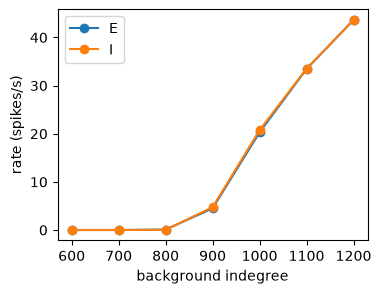

In [2]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(4, 3))
for population in ["E", "I"]:
    ax.plot(indegrees, [rates[k][population] for k in indegrees], "o-", label=population)
ax.set_xlabel("background indegree")
ax.set_ylabel("rate (spikes/s)")
ax.legend()
plt.show()

Up to about 800 inputs the network stays silent; with a little more it fires, and the rate then grows fast with the drive. The toy's 1000 inputs give about 20 spikes/s.

- Every value left a network model folder, `configs/network/toy_indegree_<value>/`, and a run folder in `output/`.
- The same loop works as a script, from a terminal: the toy example has one, `experiments/toy/background_drive_sweep.py`.
- To sweep a setting instead (seed, duration): [Running from a script](../scripts.md).

Next: [6 · NEST and Brian2](6_nest_and_brian2.ipynb).